# EDA — Dataset churn

Exploration du dataset de profils clients labellisés : valeurs manquantes, équilibre des classes, distributions — fondement des choix de prétraitement dans `analytics/churn_model.py`.

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine
import pandas as pd
import matplotlib.pyplot as plt

load_dotenv()  # cherche .env dans le répertoire courant puis ses parents
engine = create_engine(os.environ["DATABASE_URL"])
plt.rcParams["figure.figsize"] = (9, 4)

In [2]:
df = pd.read_sql("SELECT * FROM churn.customer_profiles", engine)
print(f"{len(df)} clients, {df.shape[1]} colonnes")
df.head()

50000 clients, 26 colonnes


,customer_id,age,gender,country,city,membership_years,login_frequency,session_duration_avg,pages_per_session,cart_abandonment_rate,...,email_open_rate,customer_service_calls,product_reviews_written,social_media_engagement_score,mobile_app_usage,payment_method_diversity,lifetime_value,credit_balance,churned,signup_quarter
0,2,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
1,3,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
2,4,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
3,5,35.0,Male,India,Delhi,3.1,29.0,51.4,NaN,19.1,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4
4,6,35.0,Male,Japan,Tokyo,3.5,6.0,21.9,6.9,74.4,...,16.0,8.0,2.0,14.3,11.2,2.0,1995.43,2418.0,1,Q1


## Valeurs manquantes par colonne

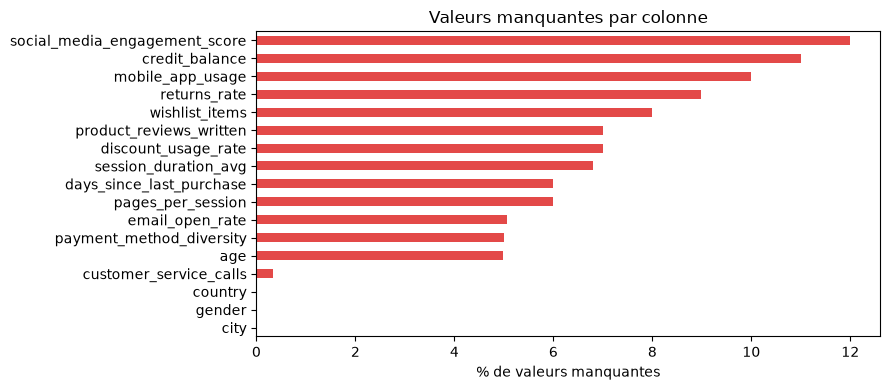

In [3]:
pct_manquant = (df.isna().mean() * 100).sort_values(ascending=False)
pct_manquant = pct_manquant[pct_manquant > 0]
ax = pct_manquant.plot.barh(color="#e34948")
ax.invert_yaxis()
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Valeurs manquantes par colonne")
plt.tight_layout()
plt.show()

## Équilibre de la cible (Churned)

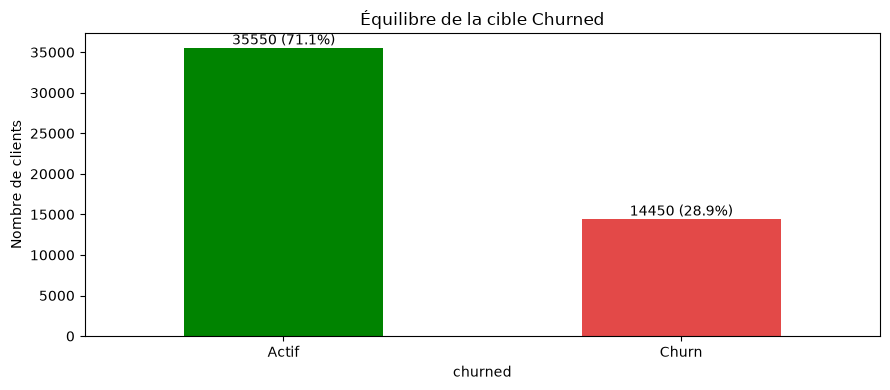

In [4]:
repartition_churn = df["churned"].value_counts().rename({0: "Actif", 1: "Churn"})
ax = repartition_churn.plot.bar(color=["#008300", "#e34948"])
for i, v in enumerate(repartition_churn):
    ax.text(i, v, f"{v} ({v/len(df)*100:.1f}%)", ha="center", va="bottom")
ax.set_ylabel("Nombre de clients")
ax.set_title("Équilibre de la cible Churned")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Distribution de quelques variables numériques clés

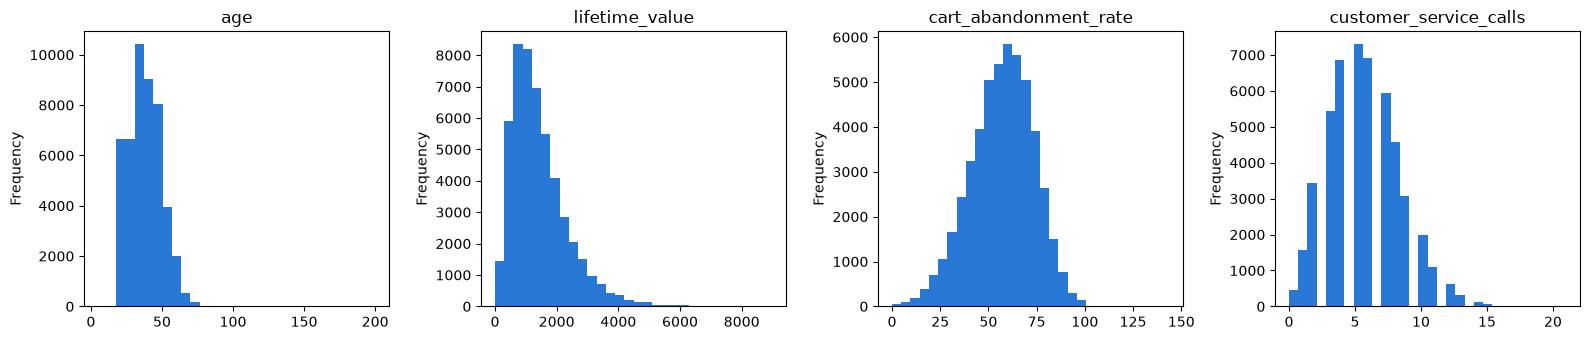

In [5]:
features = ["age", "lifetime_value", "cart_abandonment_rate", "customer_service_calls"]
fig, axes = plt.subplots(1, len(features), figsize=(16, 3.5))
for ax, col in zip(axes, features):
    df[col].dropna().plot.hist(ax=ax, bins=30, color="#2a78d6")
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Distributions comparées churn vs actif

Aperçu visuel de pourquoi ces variables ressortent comme importantes dans le Random Forest (`analytics.churn_feature_importance`, voir dashboard page Scoring churn).

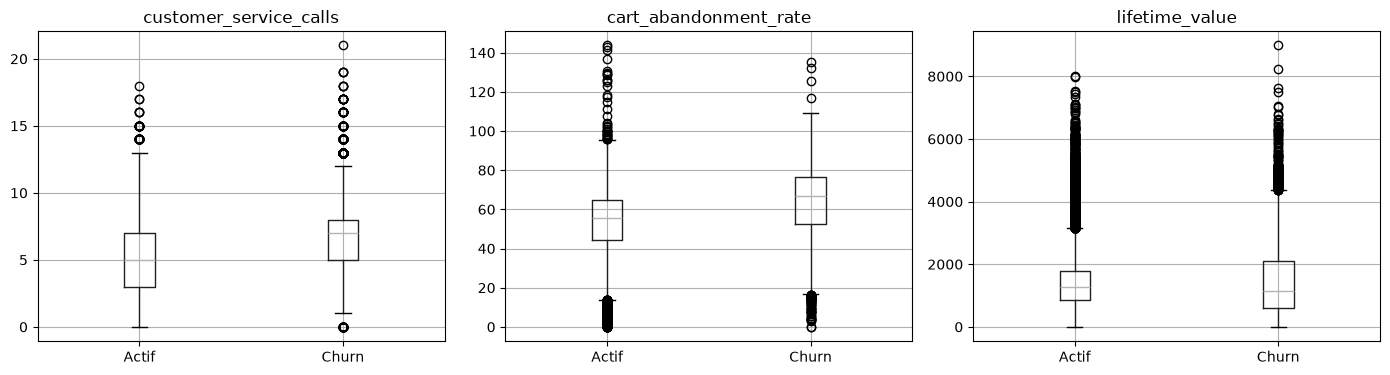

In [6]:
features = ["customer_service_calls", "cart_abandonment_rate", "lifetime_value"]
fig, axes = plt.subplots(1, len(features), figsize=(14, 4))
for ax, col in zip(axes, features):
    df.boxplot(column=col, by="churned", ax=ax)
    ax.set_xticklabels(["Actif", "Churn"])
    ax.set_xlabel("")
    ax.set_title(col)
plt.suptitle("")
plt.tight_layout()
plt.show()